# 02 · Offensive & Defensive Trends: Personnel, Concepts, Blitzes and Coverage

**Whiteboard project #2 — Year-to-year offense & defense trends.**
*Offense: personnel, run concepts, pass concepts. Defense: personnel, blitz analysis, coverage analysis. ★ What worked and what didn't?*

| Section | What it answers |
|---|---|
| 1. Build the play table | Join play-by-play, participation and FTN charting into one row per play |
| 2. How to read this notebook | Which seasons each section uses, and how "what worked" is measured |
| **Offense** | |
| 3. Personnel groupings | How often teams use 11, 12, 21… personnel, and which groupings produce |
| 4. QB alignment | Shotgun vs. under center vs. pistol |
| 5. Play design | Play action, RPOs, screens and pre-snap motion |
| 6. Pass depth | Behind the line, short, intermediate and deep throws |
| 7. Run direction | Inside vs. outside, and each gap |
| 8. Targeted routes | Which routes produce when they're thrown to |
| **Defense** | |
| 9. Defensive personnel | Base vs. nickel vs. dime |
| 10. Box count vs. the run | Light, neutral and stacked boxes |
| 11. Pass rush & blitzing | 4-man rush vs. blitz vs. dropping eight |
| 12. Coverage | Man vs. zone, and each coverage shell |
| **13. What worked & what didn't** | One summary table across everything above |

### Key terms

| Term | Meaning |
|---|---|
| **Personnel (e.g. "11")** | First digit = running backs (incl. fullbacks), second = tight ends. 11 = 1 RB, 1 TE, 3 WR. 12 = 1 RB, 2 TE, 2 WR. 21 = 2 RB, 1 TE, 2 WR. |
| **Base / Nickel / Dime** | Defensive personnel by number of defensive backs: 4 DBs = base, 5 = nickel, 6+ = dime. |
| **Box count** | Defenders lined up near the line of scrimmage at the snap. More in the box = more run support. |
| **Blitz** | 5 or more pass rushers. A standard rush is 4; "drop 8" is 3 or fewer rushers with 8 in coverage. |
| **Pressure rate** | Share of dropbacks where the QB was pressured. |
| **Man / Zone** | Whether defenders cover a specific receiver (man) or an area (zone). |
| **Cover 0 / 1 / 2 / 3 / 4 / 6** | Coverage shells, mostly named for the number of deep defenders. Cover 0 and Cover 1 are man coverage with 0 or 1 deep safety; Cover 3, Cover 4 (Quarters) and Cover 6 are zone shells; 2-Man is man underneath with two deep safeties. |
| **EPA / success rate** | Same as notebook 01: EPA per play (higher = better for the offense) and share of plays with positive EPA. For defense, **lower EPA allowed is better.** |

## Setup

Loads the shared helpers from `src/` (chart style, the readable `show()` table helper, and the play-table builder) so every notebook looks and behaves the same.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import polars as pl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from src.display import show, season_line, season_axis, COLORS, BLUE, ORANGE, INK, MUTED
from src.features import build_play_table

PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

## 1. Build the Play Table

`build_play_table()` (in `src/features.py`) takes every regular-season dropback and designed run since 2016 and attaches:

- **Participation** (2016–2025): personnel, QB alignment, box count, number of pass rushers, pressure, man/zone, coverage shell, targeted route.
- **FTN charting** (2022–present): play action, RPO, screen, pre-snap motion, number of blitzers.

It also adds readable groupings (personnel "11", "Nickel (5 DBs)", "5 (blitz)", "Deep (20+)", …). The result is saved to `data/processed/plays_enriched.parquet` so later notebooks (matchups, team kryptonite, coach deep dives) can load it directly.

In [2]:
plays = build_play_table()
plays.write_parquet(PROCESSED / "plays_enriched.parquet")

LATEST = plays["season"].max()
LAST_FULL = LATEST if plays.filter(pl.col("season") == LATEST)["week"].max() >= 18 else LATEST - 1
RECENT = list(range(LAST_FULL - 2, LAST_FULL + 1))   # last three complete seasons

print(f"{plays.height:,} plays, {plays.width} columns, seasons {plays['season'].min()}–{LATEST} ({LATEST} in progress).")
print(f"'What worked' comparisons use the last three complete seasons: {RECENT[0]}–{RECENT[-1]}.")

358,146 plays, 66 columns, seasons 2016–2026 (2026 in progress).
'What worked' comparisons use the last three complete seasons: 2023–2025.


## 2. How to Read This Notebook

**Two kinds of charts in each section:**

1. **Usage over time** (line charts): how often teams used each option, season by season. These use all plays.
2. **What worked** (bar charts and tables): EPA per play for each option over the last three complete seasons.

**Fair comparisons.** Some options are used in very different situations — heavy personnel on the goal line, blitzes on 3rd-and-long, prevent defense late in games. To compare like with like, the "what worked" numbers use **neutral situations only** (1st/2nd down, win probability 20–80%, more than 2 minutes left in the half). Set `NEUTRAL_ONLY = False` below to use every play instead.

**Sample size.** Options with fewer than `MIN_PLAYS` plays in the comparison window are left out of the bar charts.

**Season coverage by section:**

| Section | Seasons with data |
|---|---|
| Personnel, alignment, box count, pass rushers | 2016–2025 |
| Coverage (man/zone, shells) | 2018–2025 (≈84% of dropbacks before 2023, ≈100% after) |
| Play action, RPO, screens, motion, blitzers | 2022–present |
| Pass depth, run direction | 2016–present (play-by-play) |
| Targeted route | 2016–2025, most complete 2023–2025 |

In [3]:
NEUTRAL_ONLY = True
MIN_PLAYS = 300

compare = plays.filter(pl.col("season").is_in(RECENT))
if NEUTRAL_ONLY:
    compare = compare.filter(pl.col("neutral"))
print(f"Comparison set: {compare.height:,} plays ({'neutral situations' if NEUTRAL_ONLY else 'all situations'}, {RECENT[0]}–{RECENT[-1]}).")


# ---------- reusable analysis helpers ----------
def usage_by_season(df, col):
    """Share of plays (with a value for `col`) that fall in each category, per season."""
    d = df.filter(pl.col(col).is_not_null())
    return (d.group_by("season", col).agg(plays=pl.len())
             .with_columns(share=pl.col("plays") / pl.col("plays").sum().over("season"))
             .sort("season", col))


def usage_chart(ax, usage, col, order, title, ylabel):
    for i, cat in enumerate(order):
        sub = usage.filter(pl.col(col) == cat).sort("season")
        if sub.height:
            season_line(ax, sub["season"], sub["share"], LAST_FULL, COLORS[i % len(COLORS)], cat)
    ax.set_title(title)
    season_axis(ax, ylabel, pct=True)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))


def results_by(df, keys):
    """Plays, EPA, success and explosive rate for each group."""
    return (df.group_by(keys)
              .agg(plays=pl.len(), epa_per_play=pl.col("epa").mean(),
                   success_rate=pl.col("success").mean(), explosive_rate=pl.col("explosive").mean())
              .filter(pl.col("plays") >= MIN_PLAYS))


def epa_bars(ax, tbl, col, order, title, defense=False, split=True):
    """Horizontal bars of EPA per play by category; one bar per play type when split."""
    kinds = [("Dropback", BLUE), ("Designed run", ORANGE)] if split else [(None, BLUE)]
    cats = [c for c in order if c in set(tbl[col].to_list())]
    h = 0.38 if split else 0.6
    for k, (kind, color) in enumerate(kinds):
        sub = tbl if kind is None else tbl.filter(pl.col("play_kind") == kind)
        lookup = {r[col]: (r["epa_per_play"], r["plays"]) for r in sub.iter_rows(named=True)}
        ys, xs, ns = [], [], []
        for i, c in enumerate(cats):
            if c in lookup:
                ys.append(i + (k - (len(kinds) - 1) / 2) * h); xs.append(lookup[c][0]); ns.append(lookup[c][1])
        ax.barh(ys, xs, height=h * 0.9, color=color, label=kind)
        for y, x, n in zip(ys, xs, ns):
            ax.annotate(f"{x:+.3f}  (n={n:,})", (x, y), xytext=(4 if x >= 0 else -4, 0), textcoords="offset points",
                        ha="left" if x >= 0 else "right", va="center", fontsize=8, color=INK)
    ax.set_yticks(range(len(cats)), cats)
    ax.invert_yaxis()
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.35)
    ax.set_title(title)
    ax.set_xlabel("EPA allowed per play   (← better defense)" if defense else "EPA per play   (→ better offense)")
    if split:
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)


def season_pivot(df, col, order, value="epa_per_play"):
    """Category × season table of a metric (for the per-season detail tables)."""
    t = (df.filter(pl.col(col).is_in(order)).group_by("season", col)
           .agg(epa_per_play=pl.col("epa").mean(), plays=pl.len())
           .pivot(on="season", index=col, values=value, sort_columns=True))
    t = t.with_columns(pl.col(col).cast(pl.Enum([c for c in order if c in t[col].to_list()]))).sort(col)
    return t.with_columns(pl.col(col).cast(pl.String))


def season_fmt(t, f="{:+.3f}"):
    return {c: f for c in t.columns if c.isdigit()}

Comparison set: 45,248 plays (neutral situations, 2023–2025).


---
# Offense
## 3. Personnel Groupings

**Usage:** share of offensive plays run from each personnel grouping, by season. **What worked:** EPA per play from each grouping, split into dropbacks and designed runs.

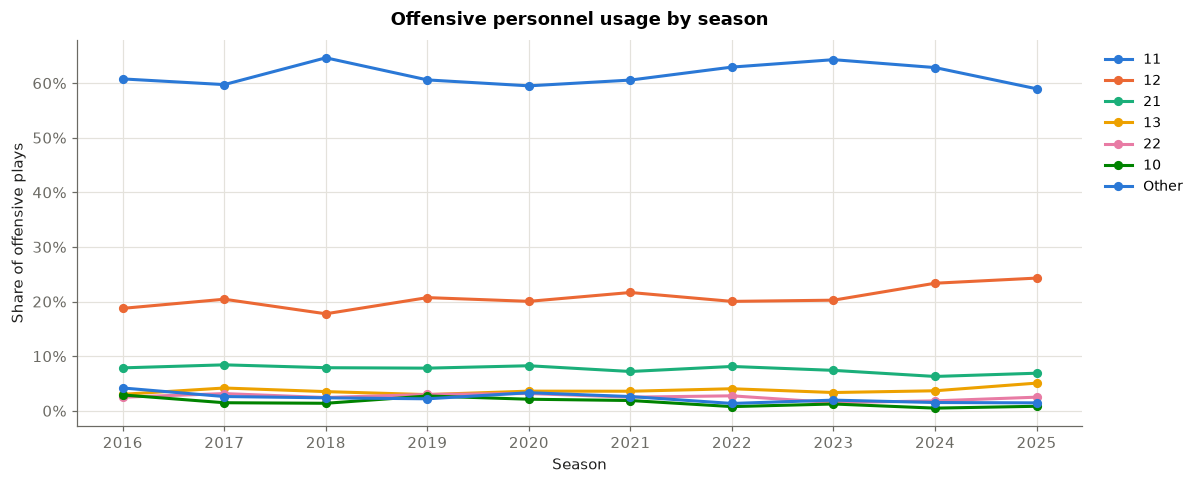

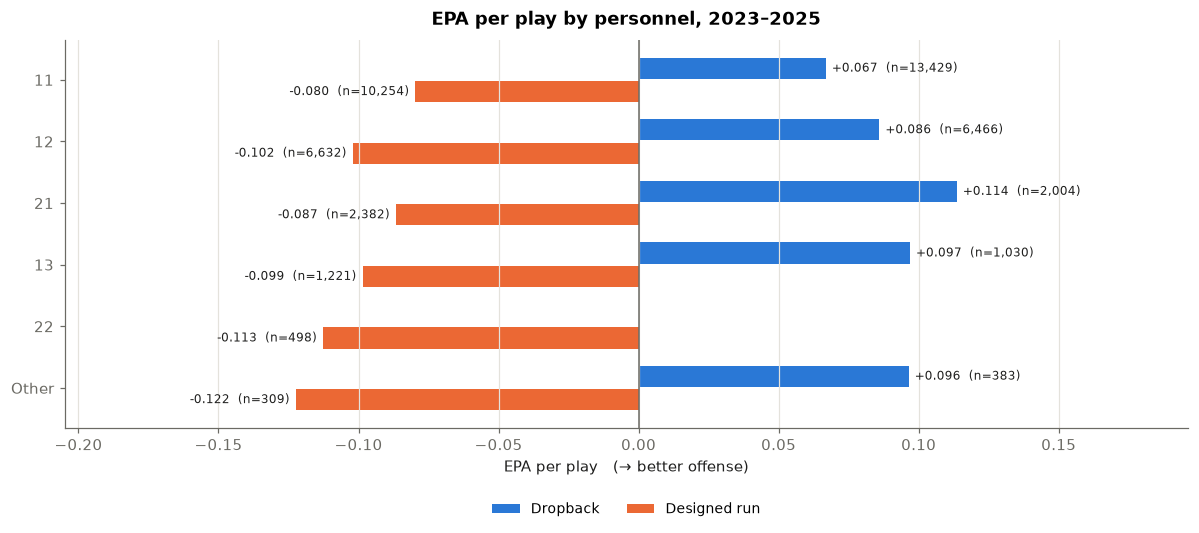

In [4]:
PERS_ORDER = ["11", "12", "21", "13", "22", "10", "Other"]

fig, ax = plt.subplots(figsize=(11, 4.5))
usage_chart(ax, usage_by_season(plays, "personnel_group"), "personnel_group", PERS_ORDER,
            "Offensive personnel usage by season", "Share of offensive plays")
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
epa_bars(ax, results_by(compare, ["personnel_group", "play_kind"]), "personnel_group", PERS_ORDER,
         f"EPA per play by personnel, {RECENT[0]}–{RECENT[-1]}")
fig.tight_layout(); plt.show()

**Detail: EPA per play by personnel, every season** (all plays, both dropbacks and runs).

In [5]:
t = season_pivot(plays, "personnel_group", PERS_ORDER)
show(t, "EPA per play by personnel grouping and season", labels={"personnel_group": "Personnel"}, fmt=season_fmt(t),
     note="All situations, dropbacks and designed runs combined. Personnel data ends in 2025.")

Personnel,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
11,+0.018,-0.019,+0.018,+0.006,+0.049,+0.027,+0.000,-0.022,+0.017,+0.029
12,-0.011,-0.014,+0.024,-0.004,+0.031,-0.030,-0.010,-0.027,+0.006,-0.017
21,-0.005,-0.023,-0.002,-0.006,+0.045,+0.005,+0.014,+0.002,+0.024,+0.008
13,-0.006,-0.110,-0.018,-0.030,-0.036,+0.021,-0.023,-0.055,-0.025,+0.011
22,+0.003,-0.028,-0.033,+0.003,+0.003,+0.007,-0.043,+0.020,+0.060,+0.051
10,-0.035,-0.033,+0.023,-0.017,+0.101,+0.091,+0.074,+0.015,-0.191,+0.020
Other,+0.059,-0.112,-0.007,-0.062,+0.082,-0.054,-0.033,-0.015,+0.040,-0.028


## 4. QB Alignment: Shotgun, Under Center, Pistol

Where the quarterback lines up at the snap. Older seasons used formation names (Singleback, I-Form, Empty…); they're mapped to the same three alignments so every season is comparable.

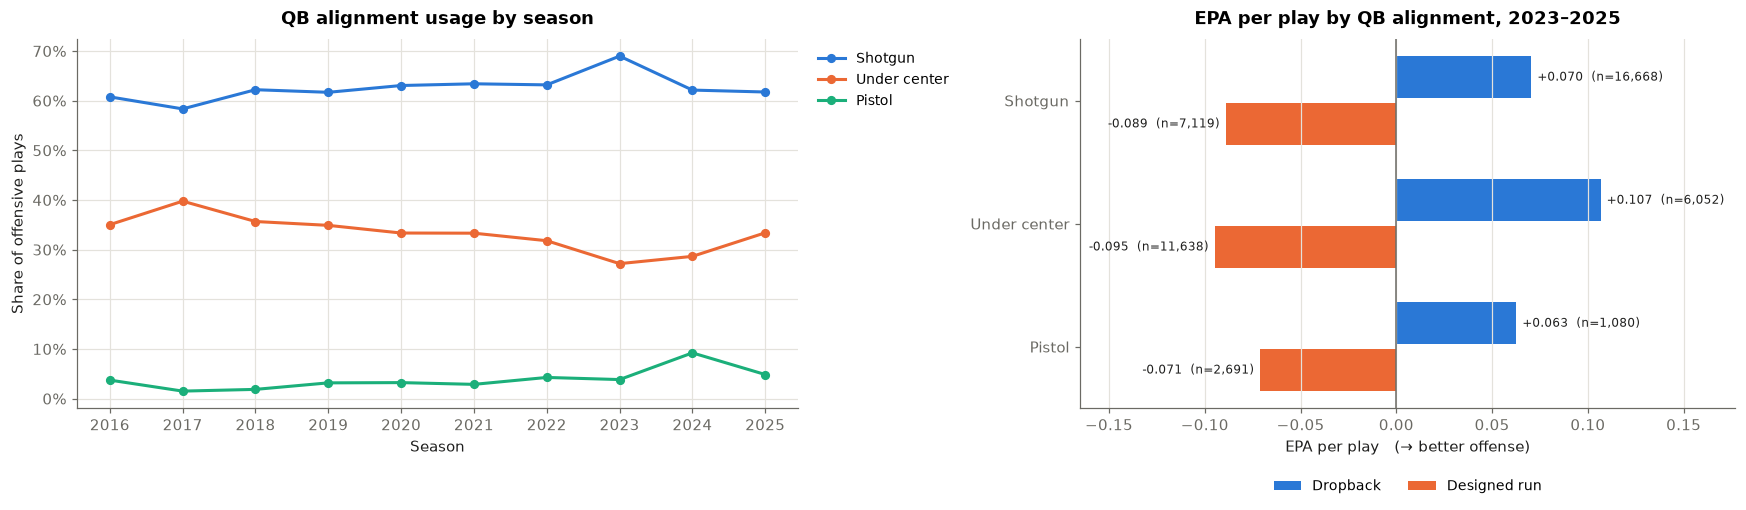

In [6]:
ALIGN_ORDER = ["Shotgun", "Under center", "Pistol"]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
usage_chart(axes[0], usage_by_season(plays.filter(pl.col("season") <= 2025), "alignment"), "alignment", ALIGN_ORDER,
            "QB alignment usage by season", "Share of offensive plays")
epa_bars(axes[1], results_by(compare, ["alignment", "play_kind"]), "alignment", ALIGN_ORDER,
         f"EPA per play by QB alignment, {RECENT[0]}–{RECENT[-1]}")
fig.tight_layout(); plt.show()

## 5. Play Design: Play Action, RPOs, Screens, Motion (2022–present)

From FTN charting. For each concept: how often it's used, and EPA per play **with** vs. **without** it.

- **Play action** and **screens** are measured among dropbacks.
- **RPOs** and **pre-snap motion** are measured among all plays.

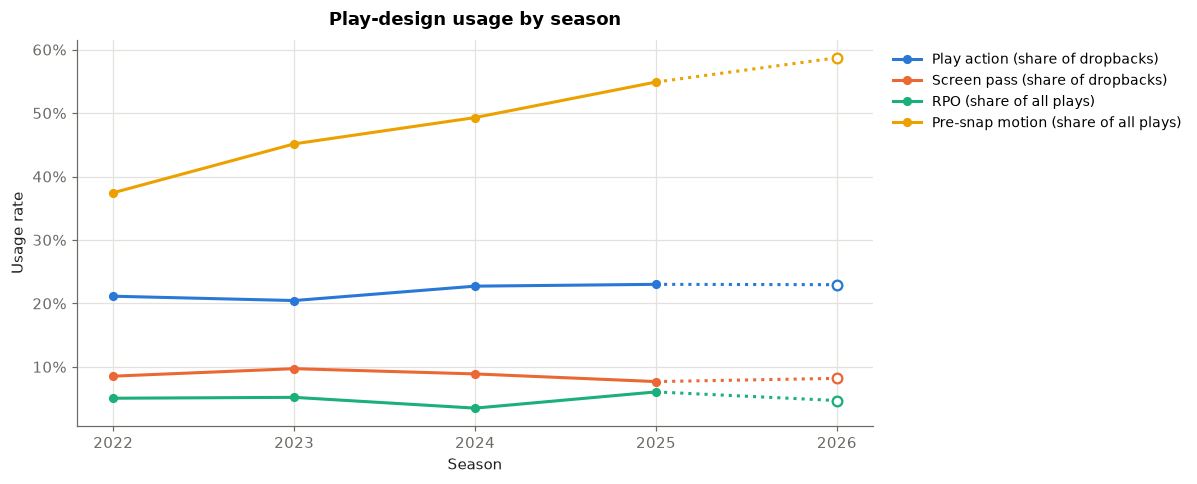

Concept,Measured Among,Usage Rate,Plays With,EPA / Play With,EPA / Play Without,Difference (With − Without),Success Rate With,Success Rate Without
Play action,dropbacks,37.3%,"8,868",+0.117,+0.057,+0.060,49.0%,48.4%
Screen pass,dropbacks,11.8%,"2,809",-0.053,+0.097,-0.150,42.1%,49.5%
RPO,all plays,6.3%,"2,835",-0.039,+0.002,-0.041,40.5%,43.9%
Pre-snap motion,all plays,56.0%,"25,326",+0.003,-0.006,+0.009,44.1%,43.2%


In [7]:
CONCEPTS = [
    ("Play action", "is_play_action", pl.col("pass") == 1, "dropbacks"),
    ("Screen pass", "is_screen_pass", pl.col("pass") == 1, "dropbacks"),
    ("RPO", "is_rpo", pl.lit(True), "all plays"),
    ("Pre-snap motion", "is_motion", pl.lit(True), "all plays"),
]

# usage by season
fig, ax = plt.subplots(figsize=(11, 4.5))
for i, (name, flag, base, among) in enumerate(CONCEPTS):
    u = (plays.filter(base & pl.col(flag).is_not_null()).group_by("season")
              .agg(rate=pl.col(flag).mean()).sort("season"))
    season_line(ax, u["season"], u["rate"], LAST_FULL, COLORS[i], f"{name} (share of {among})")
ax.set_title("Play-design usage by season")
season_axis(ax, "Usage rate", pct=True)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
fig.tight_layout(); plt.show()

# with vs without
rows = []
for name, flag, base, among in CONCEPTS:
    d = compare.filter(base & pl.col(flag).is_not_null())
    w, wo = d.filter(pl.col(flag)), d.filter(~pl.col(flag))
    rows.append({"concept": name, "measured_among": among, "usage": d[flag].mean(),
                 "plays_with": w.height, "epa_with": w["epa"].mean(), "epa_without": wo["epa"].mean(),
                 "epa_diff": w["epa"].mean() - wo["epa"].mean(),
                 "success_with": w["success"].mean(), "success_without": wo["success"].mean()})
show(pl.DataFrame(rows), f"Play design: results with vs. without, {RECENT[0]}–{RECENT[-1]}",
     labels={"concept": "Concept", "measured_among": "Measured Among", "usage": "Usage Rate", "plays_with": "Plays With",
             "epa_with": "EPA / Play With", "epa_without": "EPA / Play Without", "epa_diff": "Difference (With − Without)",
             "success_with": "Success Rate With", "success_without": "Success Rate Without"},
     pct=("success_with", "success_without"), ints=("plays_with",),
     note=("Neutral situations only. " if NEUTRAL_ONLY else "") + "Positive difference = the concept produced more EPA per play.")

## 6. Pass Depth

How far downfield the ball traveled in the air on pass attempts (air yards). **Usage** = share of attempts at each depth; **What worked** = EPA per attempt. Sacks and scrambles have no air yards, so they're excluded here.

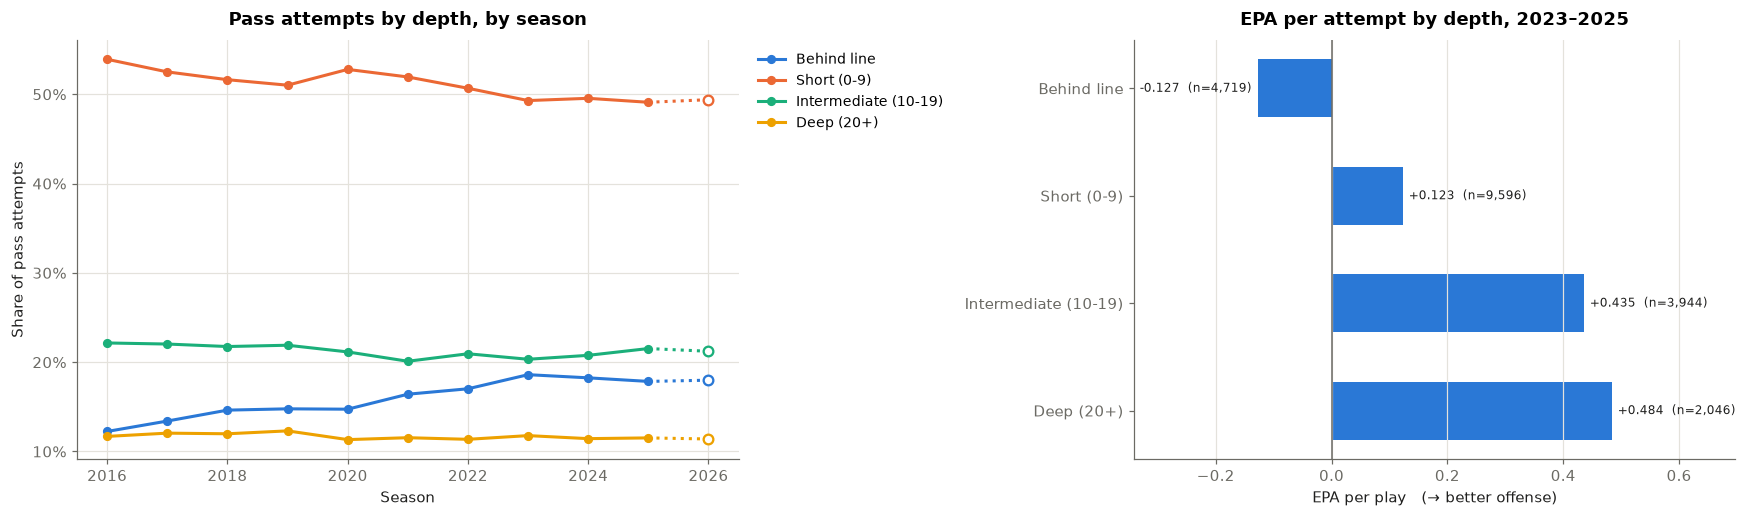

In [8]:
DEPTH_ORDER = ["Behind line", "Short (0-9)", "Intermediate (10-19)", "Deep (20+)"]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
usage_chart(axes[0], usage_by_season(plays, "depth"), "depth", DEPTH_ORDER,
            "Pass attempts by depth, by season", "Share of pass attempts")
epa_bars(axes[1], results_by(compare, ["depth"]), "depth", DEPTH_ORDER,
         f"EPA per attempt by depth, {RECENT[0]}–{RECENT[-1]}", split=False)
fig.tight_layout(); plt.show()

## 7. Run Direction

The free data records **where** a run went (left/right × end/tackle/guard, or middle), not the blocking scheme. True run *concepts* (inside zone, outside zone, power, counter) would need charting data such as PFF; direction is the closest available proxy. **Inside** = middle and guard gaps, **outside** = tackle and end.

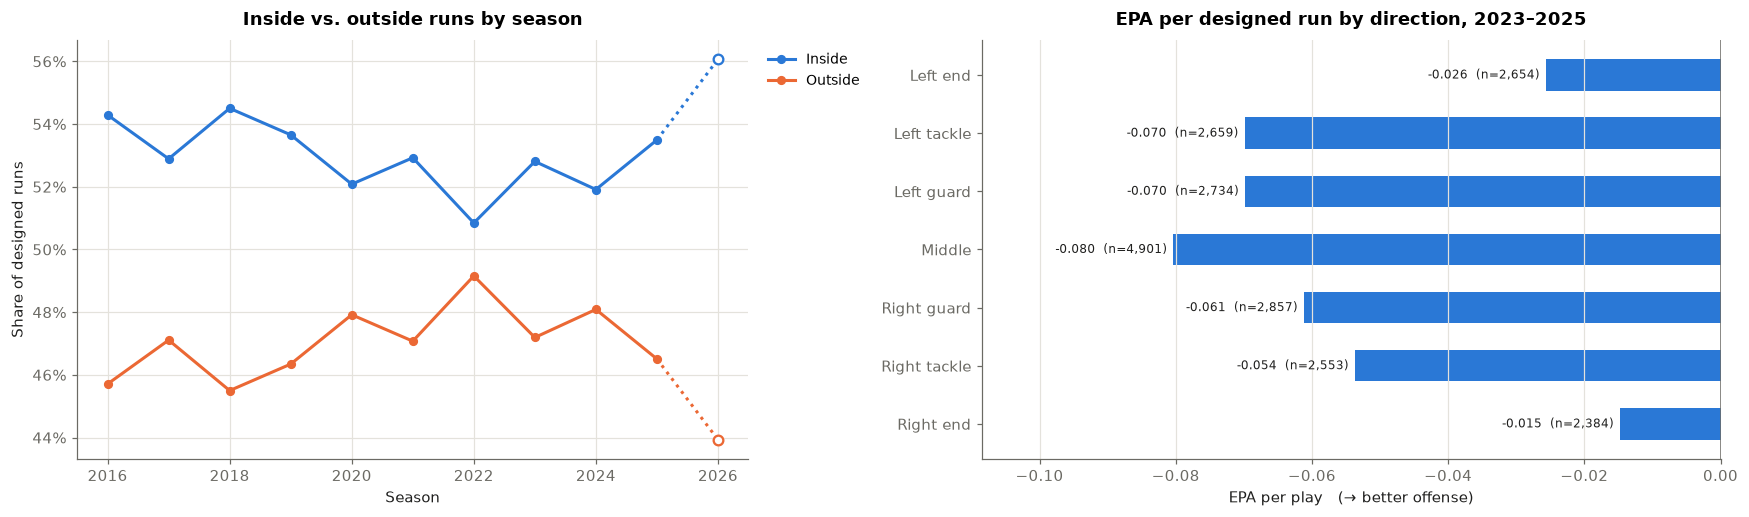

In [9]:
DIR_ORDER = ["Left end", "Left tackle", "Left guard", "Middle", "Right guard", "Right tackle", "Right end"]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
usage_chart(axes[0], usage_by_season(plays, "run_lane"), "run_lane", ["Inside", "Outside"],
            "Inside vs. outside runs by season", "Share of designed runs")
epa_bars(axes[1], results_by(compare, ["run_direction"]), "run_direction", DIR_ORDER,
         f"EPA per designed run by direction, {RECENT[0]}–{RECENT[-1]}", split=False)
fig.tight_layout(); plt.show()

## 8. Targeted Routes (2023–2025)

The route run by the **targeted** receiver on pass attempts — the only route recorded per play. EPA per target, most complete in 2023–2025.

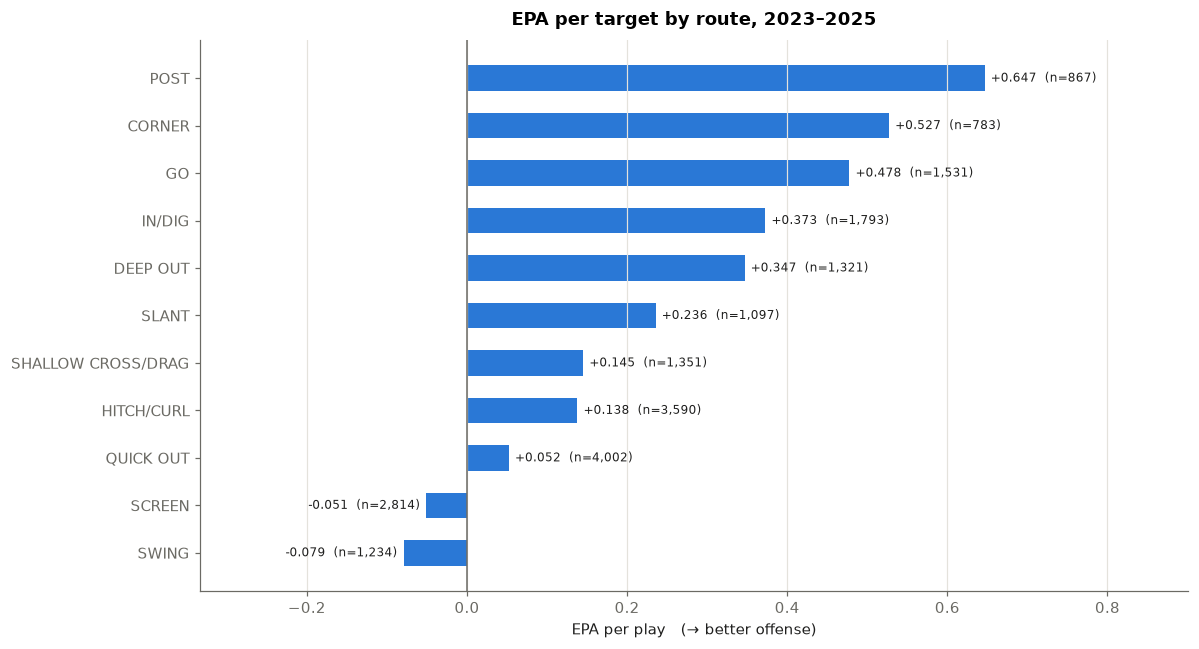

In [10]:
routes = results_by(
    plays.filter(pl.col("season").is_between(2023, 2025) & pl.col("route").is_not_null()
                 & (pl.col("neutral") if NEUTRAL_ONLY else pl.lit(True))),
    ["route"]).sort("epa_per_play", descending=True)

fig, ax = plt.subplots(figsize=(11, 6))
epa_bars(ax, routes, "route", routes["route"].to_list(), "EPA per target by route, 2023–2025", split=False)
fig.tight_layout(); plt.show()

---
# Defense

For every defensive chart and table, the numbers are what the defense **allowed**. **Lower EPA allowed is better**, so on the bar charts, bars further *left* are better defense.

## 9. Defensive Personnel: Base, Nickel, Dime

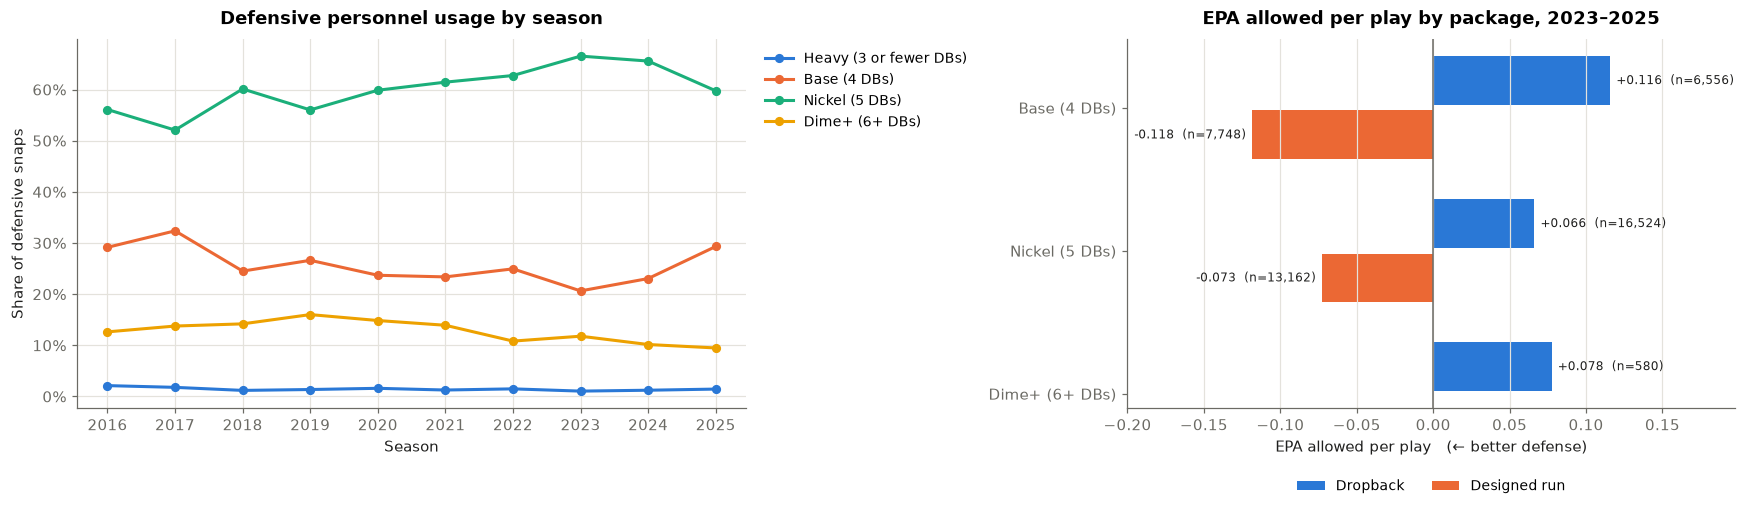

In [11]:
PKG_ORDER = ["Heavy (3 or fewer DBs)", "Base (4 DBs)", "Nickel (5 DBs)", "Dime+ (6+ DBs)"]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
usage_chart(axes[0], usage_by_season(plays, "def_package"), "def_package", PKG_ORDER,
            "Defensive personnel usage by season", "Share of defensive snaps")
epa_bars(axes[1], results_by(compare, ["def_package", "play_kind"]), "def_package", PKG_ORDER,
         f"EPA allowed per play by package, {RECENT[0]}–{RECENT[-1]}", defense=True)
fig.tight_layout(); plt.show()

## 10. Box Count vs. the Run

Defenders in the box at the snap on **designed runs**. More defenders in the box usually means a harder run — but fewer defenders in coverage, which shows up on dropbacks instead.

> **Data-source change in 2023.** Participation data from 2023 on appears to come from a different charting provider (the personnel format and field list change that year). Some jumps between 2022 and 2023 — in box counts, rusher counts and coverage shells — may be partly definitional rather than real changes in how teams play. Compare seasons within 2016–2022 or within 2023–2025 when in doubt.

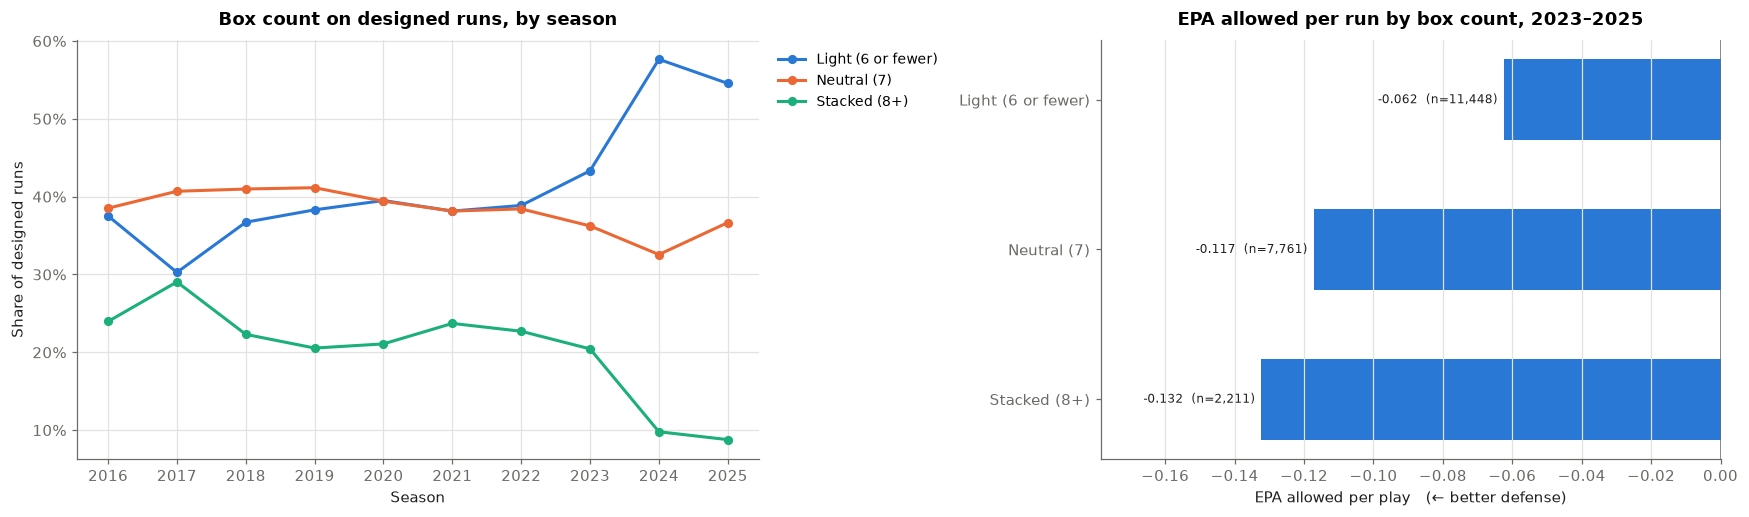

In [12]:
BOX_ORDER = ["Light (6 or fewer)", "Neutral (7)", "Stacked (8+)"]
runs = plays.filter(pl.col("rush") == 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
usage_chart(axes[0], usage_by_season(runs, "box_group"), "box_group", BOX_ORDER,
            "Box count on designed runs, by season", "Share of designed runs")
epa_bars(axes[1], results_by(compare.filter(pl.col("rush") == 1), ["box_group"]), "box_group", BOX_ORDER,
         f"EPA allowed per run by box count, {RECENT[0]}–{RECENT[-1]}", defense=True, split=False)
fig.tight_layout(); plt.show()

## 11. Pass Rush & Blitzing

Number of pass rushers on dropbacks. **Blitz** = 5 or more rushers. The table adds pressure and sack rates, which show the trade-off: blitzes get home more often but leave fewer defenders in coverage.

The FTN **blitzers** count (2022+) is a second view: the number of non-linemen (linebackers and defensive backs) who rushed.

> **Data-source change in 2023.** Participation data from 2023 on appears to come from a different charting provider (the personnel format and field list change that year). Some jumps between 2022 and 2023 — in box counts, rusher counts and coverage shells — may be partly definitional rather than real changes in how teams play. Compare seasons within 2016–2022 or within 2023–2025 when in doubt.

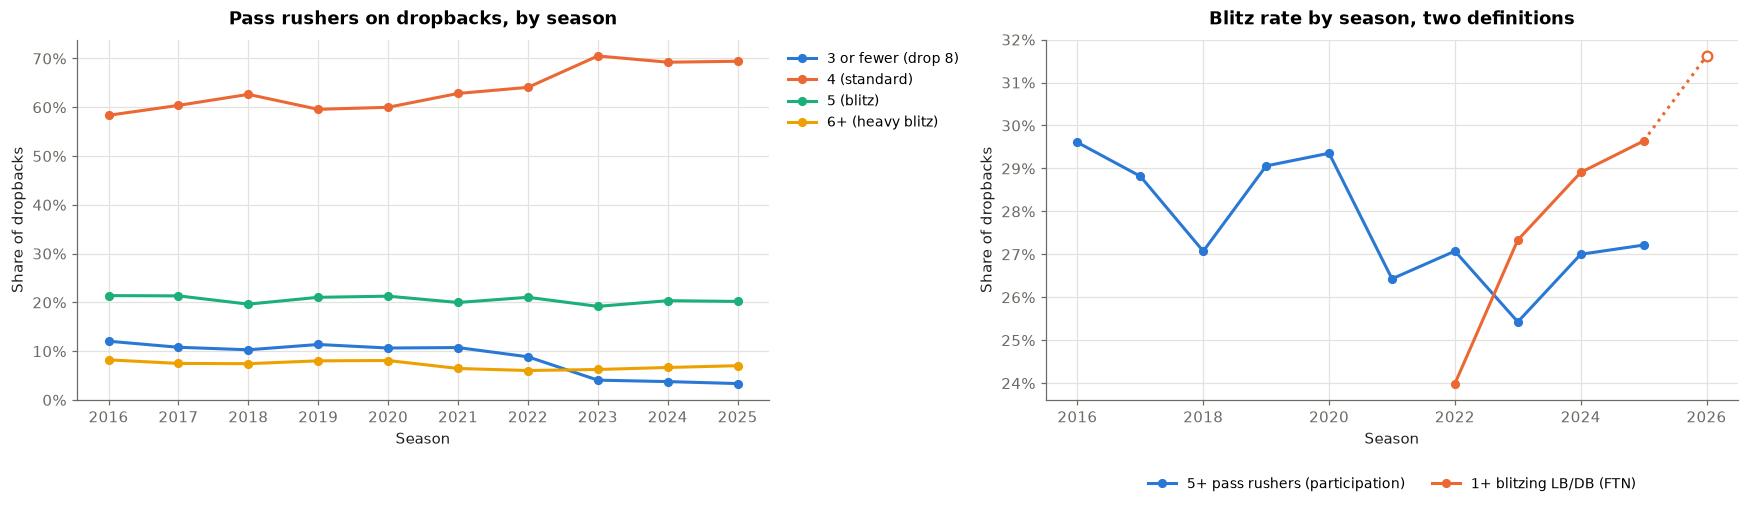

Pass Rushers,Dropbacks,Share of Dropbacks,EPA Allowed / Dropback,Success Rate Allowed,Pressure Rate,Sack Rate,Explosive Plays Allowed
3 or fewer (drop 8),633,2.7%,+0.136,47.1%,17.5%,2.4%,7.1%
4 (standard),"16,422",69.5%,+0.086,48.5%,23.9%,4.1%,7.9%
5 (blitz),"5,203",22.0%,+0.068,49.4%,35.0%,5.8%,9.0%
6+ (heavy blitz),"1,369",5.8%,+0.015,47.4%,43.4%,8.0%,7.3%


In [13]:
RUSH_ORDER = ["3 or fewer (drop 8)", "4 (standard)", "5 (blitz)", "6+ (heavy blitz)"]
dropbacks = plays.filter(pl.col("pass") == 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
usage_chart(axes[0], usage_by_season(dropbacks, "rush_group"), "rush_group", RUSH_ORDER,
            "Pass rushers on dropbacks, by season", "Share of dropbacks")

ax = axes[1]
b1 = dropbacks.filter(pl.col("blitz").is_not_null()).group_by("season").agg(rate=pl.col("blitz").mean()).sort("season")
b2 = dropbacks.filter(pl.col("n_blitzers").is_not_null()).group_by("season").agg(rate=(pl.col("n_blitzers") >= 1).mean()).sort("season")
season_line(ax, b1["season"], b1["rate"], LAST_FULL, BLUE, "5+ pass rushers (participation)")
season_line(ax, b2["season"], b2["rate"], LAST_FULL, ORANGE, "1+ blitzing LB/DB (FTN)")
ax.set_title("Blitz rate by season, two definitions")
season_axis(ax, "Share of dropbacks", pct=True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
fig.tight_layout(); plt.show()

rush_tbl = (compare.filter((pl.col("pass") == 1) & pl.col("rush_group").is_not_null())
            .group_by("rush_group")
            .agg(plays=pl.len(), share=pl.len(), epa_per_play=pl.col("epa").mean(), success_rate=pl.col("success").mean(),
                 pressure_rate=pl.col("was_pressure").mean(), sack_rate=pl.col("sack").mean(),
                 explosive_rate=pl.col("explosive").mean())
            .with_columns(share=pl.col("plays") / pl.col("plays").sum(),
                          rush_group=pl.col("rush_group").cast(pl.Enum(RUSH_ORDER)))
            .sort("rush_group").with_columns(pl.col("rush_group").cast(pl.String)))
show(rush_tbl, f"Results by number of pass rushers, {RECENT[0]}–{RECENT[-1]}",
     labels={"rush_group": "Pass Rushers", "plays": "Dropbacks", "share": "Share of Dropbacks",
             "epa_per_play": "EPA Allowed / Dropback", "success_rate": "Success Rate Allowed",
             "explosive_rate": "Explosive Plays Allowed"},
     note=("Neutral situations only. " if NEUTRAL_ONLY else "") + "Lower EPA and success allowed = better defense.")

## 12. Coverage (2018–2025)

**Man vs. zone** share of charted dropbacks by season, then each **coverage shell**. EPA allowed per dropback for each, over the last three complete seasons.

> **Data-source change in 2023.** Participation data from 2023 on appears to come from a different charting provider (the personnel format and field list change that year). Some jumps between 2022 and 2023 — in box counts, rusher counts and coverage shells — may be partly definitional rather than real changes in how teams play. Compare seasons within 2016–2022 or within 2023–2025 when in doubt.

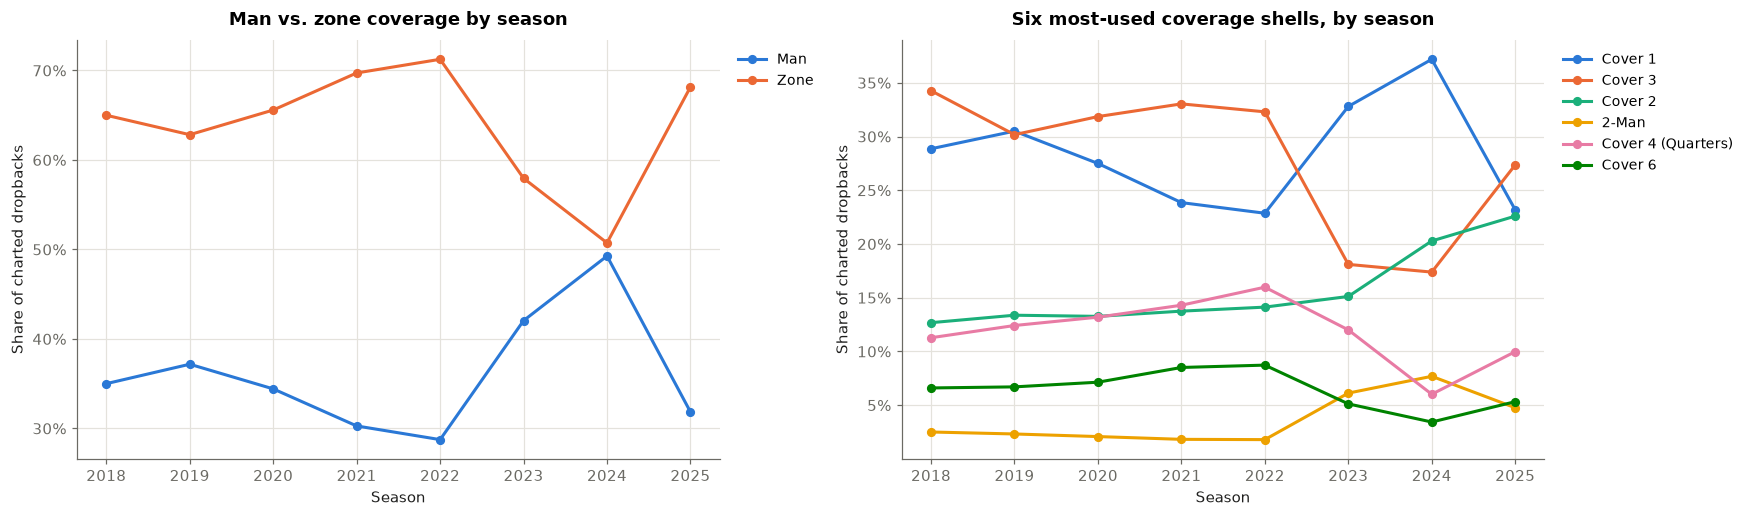

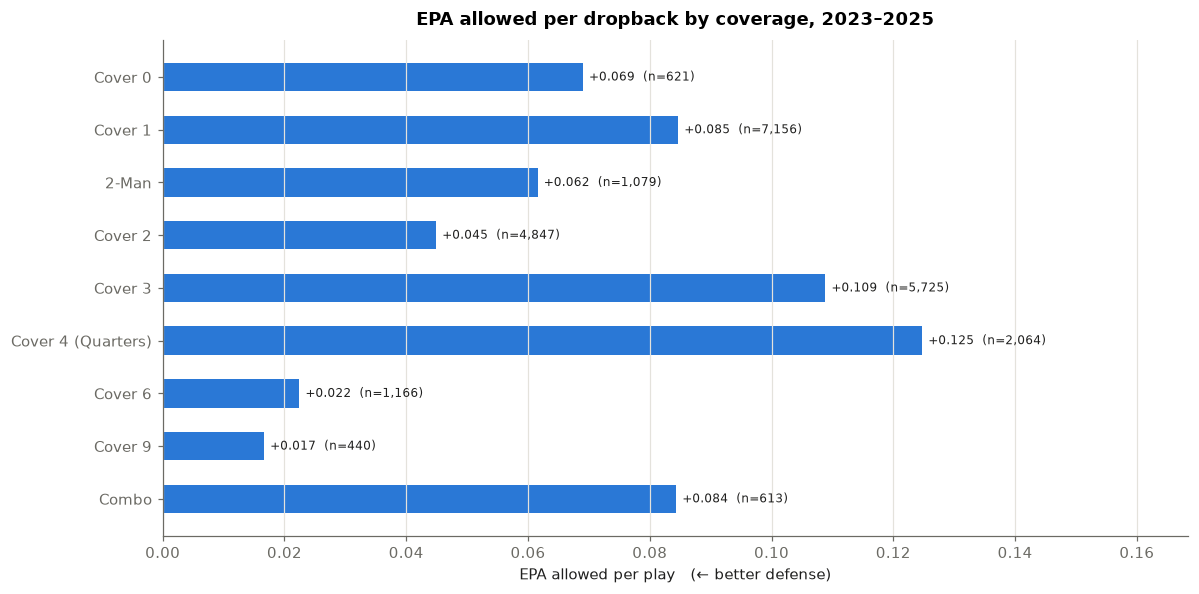

In [14]:
COV_ORDER = ["Cover 0", "Cover 1", "2-Man", "Cover 2", "Cover 3", "Cover 4 (Quarters)", "Cover 6", "Cover 9", "Combo"]
cov_drop = dropbacks.filter(pl.col("season") >= 2018)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
usage_chart(axes[0], usage_by_season(cov_drop, "man_zone"), "man_zone", ["Man", "Zone"],
            "Man vs. zone coverage by season", "Share of charted dropbacks")
top6 = ["Cover 1", "Cover 3", "Cover 2", "2-Man", "Cover 4 (Quarters)", "Cover 6"]
usage_chart(axes[1], usage_by_season(cov_drop.filter(pl.col("coverage").is_in(COV_ORDER)), "coverage"), "coverage", top6,
            "Six most-used coverage shells, by season", "Share of charted dropbacks")
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(11, 5.5))
epa_bars(ax, results_by(compare.filter(pl.col("pass") == 1), ["coverage"]), "coverage", COV_ORDER,
         f"EPA allowed per dropback by coverage, {RECENT[0]}–{RECENT[-1]}", defense=True, split=False)
fig.tight_layout(); plt.show()

**Detail: EPA allowed per dropback by coverage, every season.**

In [15]:
t = season_pivot(cov_drop, "coverage", COV_ORDER)
show(t, "EPA allowed per dropback by coverage shell and season", labels={"coverage": "Coverage"}, fmt=season_fmt(t),
     note="All situations. 2018–2022 cover ~84% of dropbacks; 2023–2025 ~100%. Lower = better defense.")

Coverage,2018,2019,2020,2021,2022,2023,2024,2025
Cover 0,+0.061,+0.035,+0.119,+0.106,-0.046,+0.038,+0.081,+0.122
Cover 1,+0.178,+0.159,+0.176,+0.157,+0.149,+0.038,+0.083,+0.111
2-Man,+0.184,+0.121,+0.213,+0.084,+0.140,+0.007,+0.079,+0.096
Cover 2,+0.171,+0.144,+0.212,+0.146,+0.084,+0.049,+0.013,+0.005
Cover 3,+0.183,+0.180,+0.201,+0.150,+0.144,+0.048,+0.083,+0.070
Cover 4 (Quarters),+0.115,+0.173,+0.134,+0.161,+0.087,-0.028,+0.141,+0.083
Cover 6,+0.239,+0.186,+0.147,+0.117,+0.147,-0.009,+0.113,-0.005
Cover 9,—,—,—,—,—,-0.124,+0.034,-0.018
Combo,—,—,—,—,—,+0.017,-0.033,+0.003


---
## 13. ★ What Worked & What Didn't

One row per dimension, pulled from everything above, over the last three complete seasons:

- **Best / worst option** by EPA per play (offense: highest is best; defense: lowest EPA allowed is best), among options with at least `MIN_PLAYS` plays.
- **Rising / falling in usage:** the option whose share of plays changed most between the first and last complete season that dimension has data for.

Read this as a map of where to dig next — the matchup questions (which concepts beat which coverages and blitzes) come in the next notebook.

In [16]:
DIMENSIONS = [
    # name, side, column, which plays (dropbacks / runs) the row covers.
    # Personnel, alignment and defensive packages are split by play type so a pass-heavy grouping
    # isn't rated "best" just because dropbacks average more EPA than runs.
    ("Personnel (dropbacks)", "Offense", "personnel_group", pl.col("pass") == 1),
    ("Personnel (runs)", "Offense", "personnel_group", pl.col("rush") == 1),
    ("QB alignment (dropbacks)", "Offense", "alignment", pl.col("pass") == 1),
    ("QB alignment (runs)", "Offense", "alignment", pl.col("rush") == 1),
    ("Pass depth", "Offense", "depth", pl.col("pass") == 1),
    ("Run direction", "Offense", "run_direction", pl.col("rush") == 1),
    ("Targeted route", "Offense", "route", pl.col("pass") == 1),
    ("Defensive personnel (vs. dropbacks)", "Defense", "def_package", pl.col("pass") == 1),
    ("Defensive personnel (vs. runs)", "Defense", "def_package", pl.col("rush") == 1),
    ("Box count (vs. runs)", "Defense", "box_group", pl.col("rush") == 1),
    ("Pass rushers", "Defense", "rush_group", pl.col("pass") == 1),
    ("Man vs. zone", "Defense", "man_zone", pl.col("pass") == 1),
    ("Coverage shell", "Defense", "coverage", pl.col("pass") == 1),
]

rows = []
for name, side, col, flt in DIMENSIONS:
    res = results_by(compare.filter(flt & pl.col(col).is_not_null()), [col]).sort("epa_per_play", descending=(side == "Offense"))
    u = usage_by_season(plays.filter(flt & (pl.col("season") <= LAST_FULL)), col)
    first, last = u["season"].min(), u["season"].max()
    delta = (u.filter(pl.col("season") == last).select(col, pl.col("share").alias("last"))
              .join(u.filter(pl.col("season") == first).select(col, pl.col("share").alias("first")), on=col, how="full", coalesce=True)
              .fill_null(0).with_columns(change=pl.col("last") - pl.col("first")).sort("change"))
    rows.append({
        "dimension": name, "side": side,
        "best": f"{res[0, col]}  ({res[0, 'epa_per_play']:+.3f})",
        "worst": f"{res[-1, col]}  ({res[-1, 'epa_per_play']:+.3f})",
        "rising": f"{delta[-1, col]}  ({delta[-1, 'change'] * 100:+.1f} pts)",
        "falling": f"{delta[0, col]}  ({delta[0, 'change'] * 100:+.1f} pts)",
        "usage_window": f"{first}–{last}",
    })

show(pl.DataFrame(rows), f"What worked and what didn't, {RECENT[0]}–{RECENT[-1]}",
     labels={"dimension": "Dimension", "side": "Side", "best": "Best Option (EPA / Play)", "worst": "Worst Option (EPA / Play)",
             "rising": "Biggest Usage Increase", "falling": "Biggest Usage Decrease", "usage_window": "Usage Change Measured"},
     note=("Neutral situations only. " if NEUTRAL_ONLY else "") +
          "Defense: best = lowest EPA allowed. Usage change is in percentage points of share between the first and last season measured.")

Dimension,Side,Best Option (EPA / Play),Worst Option (EPA / Play),Biggest Usage Increase,Biggest Usage Decrease,Usage Change Measured
Personnel (dropbacks),Offense,21 (+0.114),11 (+0.067),12 (+4.7 pts),Other (-3.3 pts),2016–2025
Personnel (runs),Offense,11 (-0.080),Other (-0.122),12 (+6.4 pts),11 (-3.3 pts),2016–2025
QB alignment (dropbacks),Offense,Under center (+0.107),Pistol (+0.063),Shotgun (+1.1 pts),Under center (-1.5 pts),2016–2025
QB alignment (runs),Offense,Pistol (-0.071),Under center (-0.095),Shotgun (+2.9 pts),Under center (-3.7 pts),2016–2025
Pass depth,Offense,Deep (20+) (+0.484),Behind line (-0.127),Behind line (+5.6 pts),Short (0-9) (-4.8 pts),2016–2025
Run direction,Offense,Right end (-0.015),Middle (-0.080),Right tackle (+1.0 pts),Middle (-1.7 pts),2016–2025
Targeted route,Offense,POST (+0.647),SWING (-0.079),QUICK OUT (+18.5 pts),GO (-15.1 pts),2016–2025
Defensive personnel (vs. dropbacks),Defense,Nickel (5 DBs) (+0.066),Base (4 DBs) (+0.116),Nickel (5 DBs) (+4.2 pts),Dime+ (6+ DBs) (-3.8 pts),2016–2025
Defensive personnel (vs. runs),Defense,Base (4 DBs) (-0.118),Nickel (5 DBs) (-0.073),Nickel (5 DBs) (+3.3 pts),Heavy (3 or fewer DBs) (-1.6 pts),2016–2025
Box count (vs. runs),Defense,Stacked (8+) (-0.132),Light (6 or fewer) (-0.062),Light (6 or fewer) (+17.0 pts),Stacked (8+) (-15.2 pts),2016–2025


## Caveats

- **Correlation, not cause.** A concept with high EPA may be called in favorable looks (e.g. play action off a strong run game). The matchup notebook controls for the defense's call.
- **Selection.** Even within neutral situations, teams choose personnel and coverages based on the opponent and down & distance.
- **Run concepts.** Only run *direction* is in the free data, not blocking scheme.
- **Charting source change in 2023.** Box counts, rusher counts, man/zone and coverage shells shift sharply between 2022 and 2023, likely partly because the data provider changed. The "what worked" window (2023–2025) sits entirely after the change.
- **Coverage before 2023** is charted on ~84% of dropbacks, so early seasons have slightly smaller samples.

## Next

- **03 · Matchups:** which offensive concepts (personnel, play action, depth, routes) beat which coverages and blitzes — and which coverages and blitzes beat which concepts. Uses `data/processed/plays_enriched.parquet` from this notebook.